# Generative AI and LLM Fundamentals

## 1. What is Generative AI?

### Explanation

**Artificial Intelligence (AI)** is a broad area of computing that builds systems able to perform tasks that normally require human-like abilities, such as recognizing patterns, understanding language, or making predictions.

**Generative AI (GenAI)** is a type of AI that can create new content based on patterns learned from examples. It can produce text, code, images, audio, video, and other kinds of content, depending on the model.

A useful difference:

- A **classification system** might decide whether an email is spam or not spam.
- A **generative system** might draft a reply to that email.

Generative AI does not simply copy a fixed answer for every question. It generates an output based on the input, its learned patterns, and its configuration. The output can still be wrong, so important results need checking.

### Flow chart

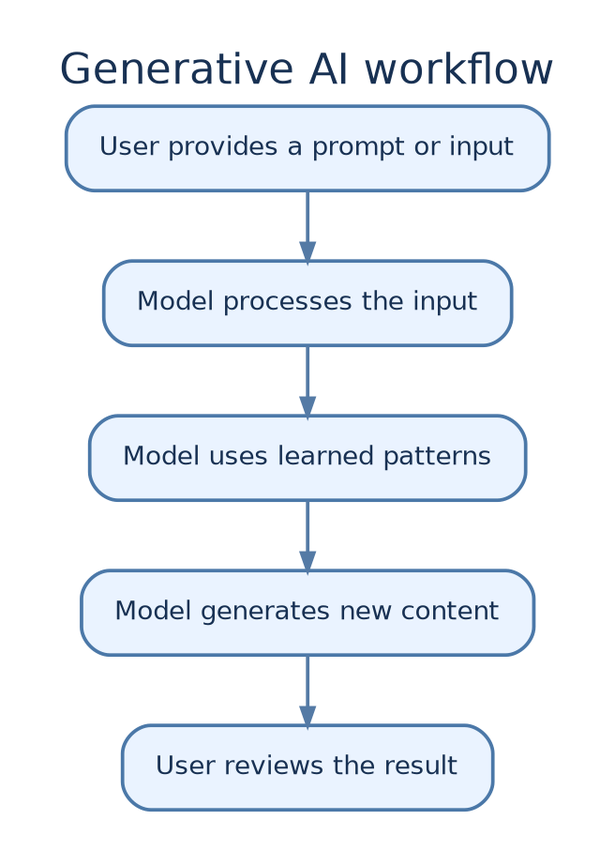

### Real-world examples

- **Writing:** Draft an email or rewrite a paragraph politely.
- **Programming:** Explain code or suggest a function.
- **Business:** Summarize a meeting transcript.
- **Education:** Explain a difficult concept in beginner-friendly language.
- **Images:** Generate an illustration from a text description.

### Example

This is a tiny rule-based demonstration of the *idea* of generating content. It is not a real GenAI model.

In [ ]:
request = "Write a polite reply to a customer whose delivery is late."

# A simple template demonstrates how an application might build a response.
# A real generative model would produce text based on learned patterns.
if "late" in request.lower():
    draft = "I'm sorry your delivery is delayed. Thank you for your patience while we check the status."
else:
    draft = "Thank you for contacting us. How can we help?"

print("Request:", request)
print("Generated-style draft:", draft)

## 2. What is a Large Language Model (LLM)?

### Explanation

A **Large Language Model (LLM)** is a model trained on a very large collection of text and/or other data, depending on the model. Training helps it learn patterns in language, facts represented in its training material, styles, and relationships between words and ideas.

A common way an LLM generates text is by predicting a likely next **token** from the tokens already provided. It then adds a token and repeats the process. Many small choices build a sentence or longer answer.

For example, after the text `The sky is`, likely next words may include `blue` or `cloudy`, depending on context. The model does not simply search a database for one exact stored sentence; it calculates likely continuations from learned patterns and current context.

An LLM is not the same as a database:

- A database stores records that can be queried directly.
- An LLM generates responses from learned patterns and the context it receives.
- An LLM can sound confident and still be wrong; a database query can also be wrong if the data or query is wrong, but it is a different kind of system.

### Flow chart

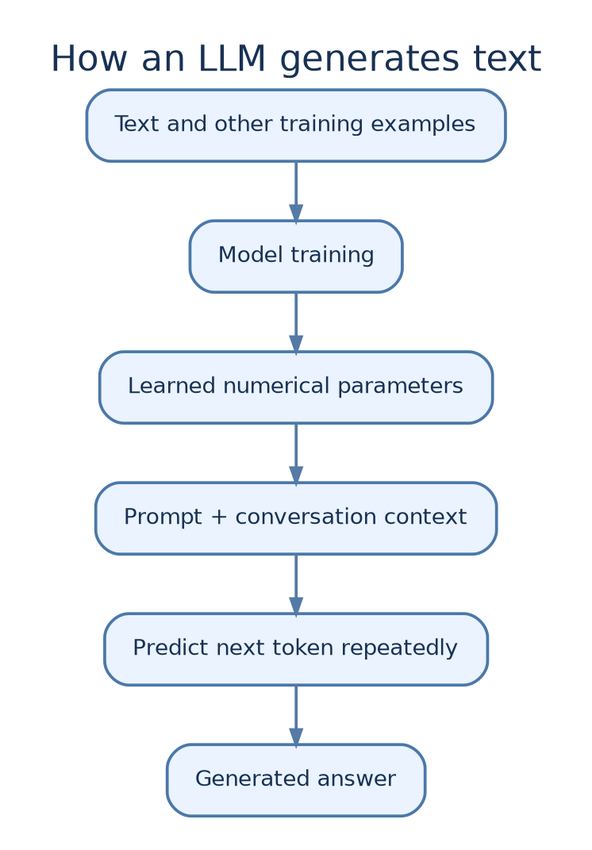

### Real-world example

A help-desk application receives: `How do I reset my password?` The LLM can generate a friendly explanation using the instructions and trusted support information supplied to it. For exact account status, the application may still need to query a real account system.

### Example

The next-token list below is manually written to demonstrate the idea only. It does not predict tokens using a trained model.

In [ ]:
prefix = "The sky is"
possible_next_tokens = [" blue", " cloudy", " bright"]

print("Current text:", prefix)
print("Possible next tokens in this toy example:")
for token in possible_next_tokens:
    print(repr(token))

# A toy generator appends one chosen continuation.
chosen_token = possible_next_tokens[0]
print("Example continuation:", prefix + chosen_token)

## 3. Transformer architecture — conceptual level

### Explanation

A **Transformer** is a deep learning neural network architecture that processes text by analyzing relationships between words or tokens using a mechanism called self-attention. It helps a model understand the context of a sentence and is the foundation of many modern Large Language Models (LLMs), such as GPT.

1. **Tokenization:** The input text is split into tokens.
2. **Embeddings:** Tokens are converted into numerical vectors that the model can process.
3. **Position information:** The model gets information about token order, so it can distinguish different arrangements of the same words.
4. **Attention:** The model learns which other tokens are useful for interpreting a token in context. For example, in `The dog chased the ball because it was excited`, context helps interpret what `it` refers to.
5. **Neural-network processing:** Transformer layers transform the representations to learn useful patterns.
6. **Output scores:** The model produces scores for possible next tokens; generation settings help select a token.
7. **Repeat:** The process continues until the response is finished or a stopping limit is reached.

Attention is not human attention or proof that the model understands in the same way a person does. It is a mathematical operation that combines information from different positions in the input.

### Flow chart

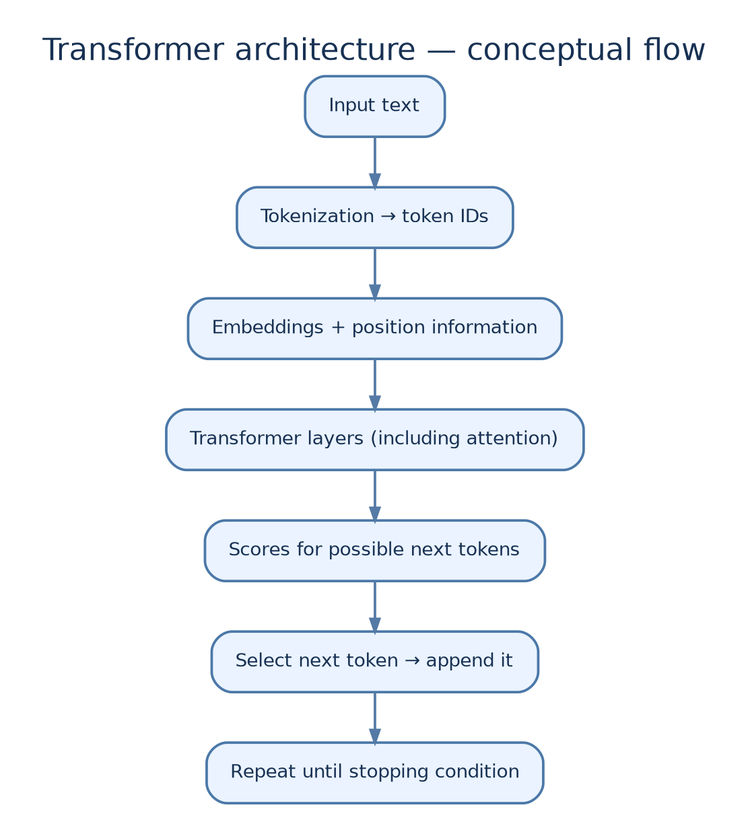

### Real-world example

Compare `The student gave the teacher a book because she asked for it` with other context. The surrounding words help a language model work out likely relationships between words. Ambiguous sentences can still be misunderstood.

### Example: a tiny attention illustration

The code below uses made-up vectors and weights to show the idea of combining information. It is **not** a Transformer implementation.

In [ ]:
# Toy example: imagine a word can use information from three other words.
words = ["The", "dog", "barked"]
attention_weights = [0.1, 0.7, 0.2]  # illustrative weights, not learned values

print("Words:", words)
print("Illustrative attention weights:", attention_weights)
print("Weights sum to:", round(sum(attention_weights), 2))
print("The largest weight is assigned to:", words[attention_weights.index(max(attention_weights))])

# In a real Transformer, attention weights are calculated from learned representations.
# They are not manually assigned like these demonstration values.

## 4. Tokens, tokenization, and context windows

### Explanation

A **token** is a small unit of text processed by a language model. A token may be a whole word, part of a word, punctuation, or another text unit. A token is **not always one word or one character**.

**Tokenization** is the process of splitting text into tokens. Different models can use different tokenizers, so the same sentence can have different token counts in different models.

A **context window** is the amount of tokenized information a model can consider in one request. It may include instructions, the user's message, previous messages, documents supplied to the model, and other context. The exact limit depends on the model and may account for both input and output tokens.

If the context is too large, the application may need to shorten it, summarize earlier content, or retrieve only the most relevant information. A large context window does not mean the model will perfectly notice every detail.

### Flow chart

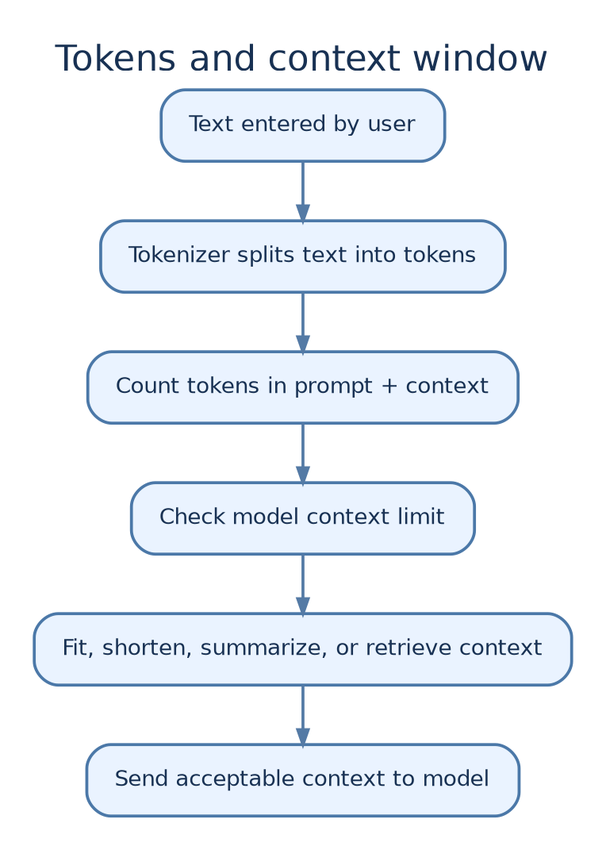

### Real-world example

A user uploads a very long policy document and asks a question about one clause. If the full document is too large for the model's context window, an application can search for the relevant section and send that section instead of sending everything.

### Example

This uses a rough regular-expression tokenizer. It is useful for learning, but it is **not the tokenizer used by a real LLM**.

In [ ]:
import re

sample_text = "Generative AI can draft emails, summarize documents, and help write code!"
rough_tokens = re.findall(r"\w+|[^\w\s]", sample_text)

print("Text:", sample_text)
print("Rough tokens:", rough_tokens)
print("Approximate token count:", len(rough_tokens))
print("Note: a real model tokenizer may split the text differently.")

# A simplified context-budget example
context_limit = 100
prompt_tokens = 35
history_tokens = 40
requested_output_tokens = 30
estimated_total = prompt_tokens + history_tokens + requested_output_tokens
print("\nEstimated total tokens:", estimated_total)
print("Fits illustrative limit?", estimated_total <= context_limit)

## 5. Embeddings and semantic similarity

### Explanation

An **embedding** is a list of numbers (a vector) that represents an item such as a word, sentence, image, or document. A trained embedding model learns to place items with useful similarities near one another in a numerical space.

For text, embeddings can help compare meaning rather than just matching exact words. For example, `How can I change my password?` and `Steps to reset a login password` use different words but have similar meanings.

**Semantic similarity** estimates how close two representations are. A common measure is **cosine similarity**, which compares the direction of two vectors. In many embedding systems, a larger cosine similarity indicates more similar representations, but the exact interpretation depends on the model and task.

Embeddings are useful for:

- Semantic search
- Finding related documents
- Grouping similar feedback
- Retrieval-augmented generation (RAG), where relevant information is retrieved before an LLM answers

Toy vectors below are manually chosen for demonstration. Real embeddings are generated by a trained model and may contain hundreds or thousands of numbers.

### Flow chart

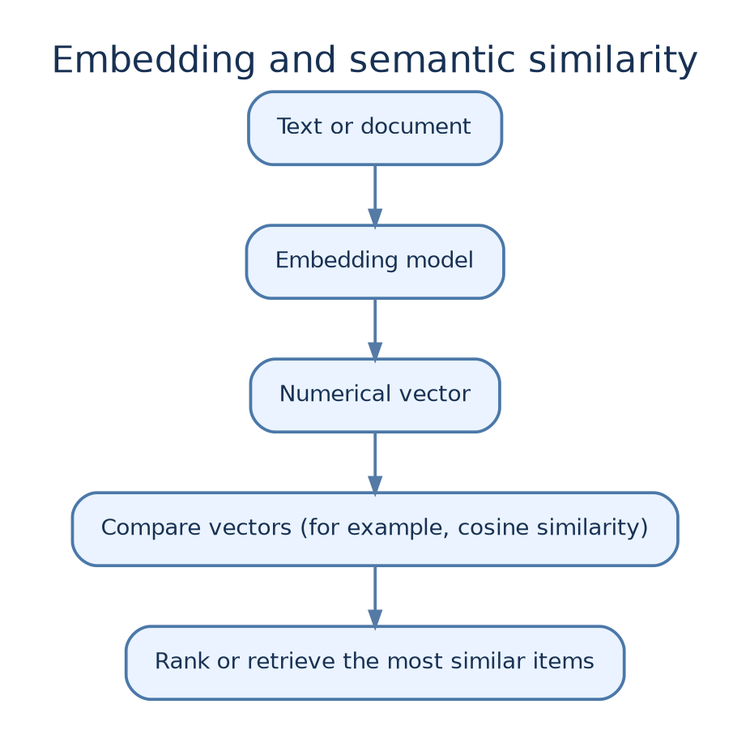

### Real-world example

A support website has 10,000 help articles. Instead of looking only for exact keyword matches, it can embed the user's question and each article, then retrieve articles whose embeddings are similar to the question.

### Example: cosine similarity

In [ ]:
import math

def cosine_similarity(a, b):
    """Return cosine similarity for two numeric vectors of equal length."""
    if len(a) != len(b):
        raise ValueError("Vectors must have the same length")
    dot = sum(x * y for x, y in zip(a, b))
    norm_a = math.sqrt(sum(x * x for x in a))
    norm_b = math.sqrt(sum(y * y for y in b))
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return dot / (norm_a * norm_b)

# Made-up vectors for learning; not real text embeddings.
password_question = [0.9, 0.8, 0.1]
password_article = [0.85, 0.75, 0.2]
weather_article = [0.1, 0.2, 0.95]

print("Question vs password article:", round(cosine_similarity(password_question, password_article), 3))
print("Question vs weather article:", round(cosine_similarity(password_question, weather_article), 3))

## 6. Prompt engineering

### Explanation

A **prompt** is the instruction and information provided to a model. **Prompt engineering** means designing and improving prompts so the task is clear and the output is useful.

A good prompt often includes:

- **Task:** What should the model do?
- **Context:** What background information should it use?
- **Constraints:** What should it include or avoid?
- **Output format:** Paragraph, bullet list, table, JSON, and so on.
- **Audience and tone:** Beginner, technical reader, friendly, formal, etc.
- **Examples:** One or more examples of the desired result, when helpful.

A vague prompt leaves many decisions to the model. A specific prompt narrows the task. However, a detailed prompt cannot guarantee correctness, and important facts should be checked.

### Flow chart

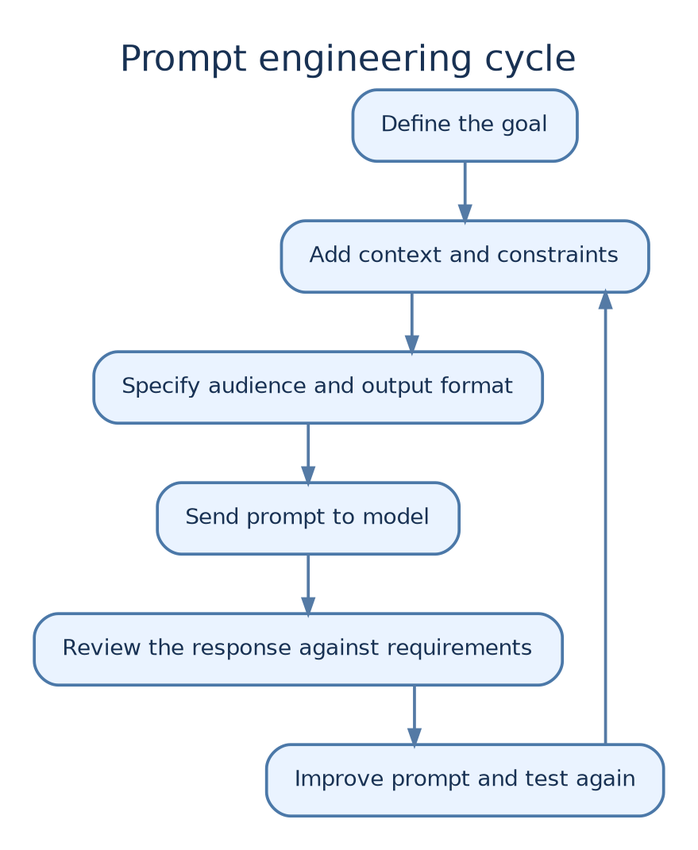

### Real-world example

Vague/Not Clear: `Summarize this feedback.`

Clearer: `Summarize the feedback below in three bullets. Identify the main complaint, the requested action, and the customer's tone. Do not invent information. If an item is missing, write "Not provided."`

### Example: compare prompt clarity

This code does not call an LLM. It shows how a prompt can be assembled from explicit requirements.

In [ ]:
task = "Summarize customer feedback"
audience = "A busy support manager"
format_rule = "Exactly 3 bullet points"
constraints = ["Mention the main complaint", "Mention requested action", "Do not invent missing details"]

improved_prompt = (
    f"Task: {task}.\n"
    f"Audience: {audience}.\n"
    f"Output: {format_rule}.\n"
    "Requirements: " + "; ".join(constraints) + "."
)
print(improved_prompt)

## 7. System, user, and assistant messages

### Explanation

Chat-based model APIs commonly represent a conversation as a sequence of messages. Each message has a **role** and content. The role tells the application/model what kind of message it is.

- **System:** High-level instructions about the assistant's behavior in systems that use this role.
- **Developer:** Instructions from the application builder about how the assistant should work. Many APIs support this role separately.
- **User:** The request or information provided by the person using the application.
- **Assistant:** Content produced by the AI assistant. It may be a user-facing answer or a tool call.
- **Tool:** A result returned by an external tool, such as a calculator or search system, when the API represents tool messages separately.

A simplified conversation might look like this:

```text
System: You are a helpful Python tutor. Explain simply.
User: What is a variable?
Assistant: A variable is a name used to refer to a value.
```

The labels `System`, `User`, and `Assistant` are role labels. The application usually displays the user's message and the assistant's final answer; it does not normally show every internal instruction or tool message. The exact roles and priority rules vary by API. Instructions do not make the model infallible, and user requests still need to be handled safely.

### Flow chart

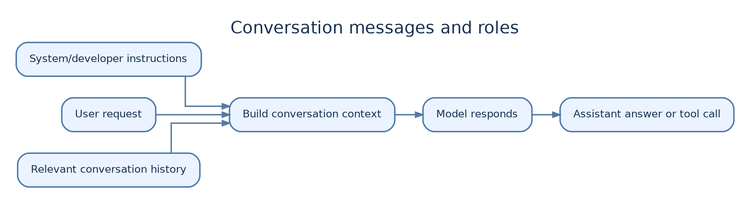

### Real-world example

A banking chatbot may have developer instructions to answer in a professional tone. The user asks how to update an address. The assistant explains the steps and may call an approved account service if identity verification is required.

### Example

In [ ]:
messages = [
    {"role": "system", "content": "You are a Python tutor. Explain concepts simply."},
    {"role": "user", "content": "What is a variable?"},
    {"role": "assistant", "content": "A variable is a name used to refer to a value."},
    {"role": "user", "content": "Give me a short example."},
]

for message in messages:
    print(f"{message['role'].upper()}: {message['content']}")

# This only represents a message history. It does not send anything to an AI API.

## 8. Temperature and other model parameters

### Explanation

Generation parameters are settings that influence how a model creates an answer. Available settings and accepted values depend on the provider and model.

#### Temperature

**Temperature influences how predictable or varied token selection tends to be.** A lower value often makes choices more concentrated on higher-probability tokens; a higher value often allows more variation. Temperature does not directly set answer length and does not guarantee correctness.

- Lower temperature can be a reasonable starting point for extraction or consistent formatting.
- Moderate temperature may work well for general responses.
- Higher temperature may help with brainstorming or creative writing.

These are starting points, not universal rules. Some models do not support temperature or restrict its values.

#### Other common settings

- **Maximum output tokens:** Limits how much the model may generate. It is a limit, not a promise that the model will use all those tokens.
- **Top-p:** Another sampling control that limits choices to a set of tokens whose cumulative probability reaches a threshold. Usually, developers tune either temperature or top-p first rather than changing many sampling controls at once.
- **Frequency penalty:** In APIs that support it, discourages reuse of tokens already used often in the output.
- **Presence penalty:** In APIs that support it, may encourage introducing tokens/topics that have appeared less or not at all.
- **Stop sequence:** A specified sequence that can end generation when encountered, where supported.
- **Seed:** A starting value for a random-number generator. A supported fixed seed can help reproduce results under the same conditions, but does not guarantee identical outputs across providers, model versions, hardware, or API implementations.
- **Response format / schema:** Some APIs can constrain output to a format such as JSON. You should still validate the result and values.

**Important distinction:** Seed `7` does not mean the AI starts at token 7. It initializes the random-number generator. A smaller seed is not more accurate than a larger one. Temperature affects the selection process; seed may help repeat the random choices.

### Flow chart

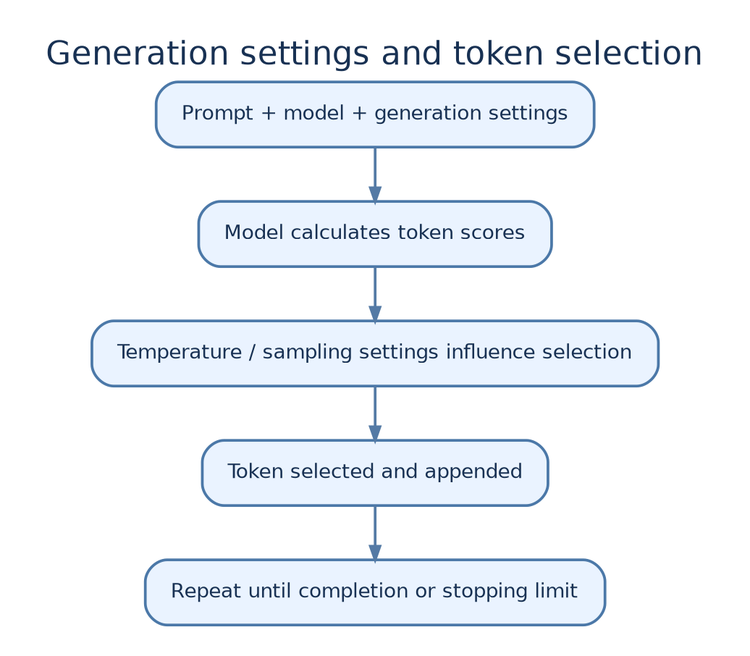

### Real-world example

For invoice extraction, you might use a low temperature, request a defined JSON structure, and set a sensible output-token limit. You should still check the extracted amount against the invoice. For creative story ideas, a higher temperature may produce more varied suggestions.

### Example: simulate the idea

This uses Python's `random` module and made-up choices. It is **not** an actual LLM temperature algorithm and does not demonstrate a provider's seed guarantees.

In [ ]:
import random

options = ["Coffee Corner", "Moonbean Cafe", "The Roasted Planet"]

# Same seed + same Python random process -> same choice in this toy demonstration.
random.seed(7)
print("Toy result with seed 7:", random.choice(options))

random.seed(7)
print("Repeat with seed 7:", random.choice(options))

random.seed(100)
print("Toy result with seed 100:", random.choice(options))

print("\nRemember: the seed is not a quality score; 7 is not better than 100.")
print("A real model API may offer only limited reproducibility.")

## 9. Structured outputs and JSON responses

### Explanation

A normal text answer is easy for a person to read, but an application may need information in a predictable structure. **Structured output** means requesting data in a defined shape, often JSON that follows a schema.

For example, a support-ticket system may need three fields: `category`, `priority`, and `needs_human`.

JSON has strict syntax rules:

- Property names and text values use double quotes.
- `true`, `false`, and `null` are lowercase and are not quoted when used as JSON values.
- Commas separate fields, but there must not be an extra comma after the last field.

Valid JSON syntax does not guarantee the values are correct. An application should check both the structure and business rules. If a model returns invalid or incomplete data, the application should handle the error instead of blindly trusting it.

### Flow chart

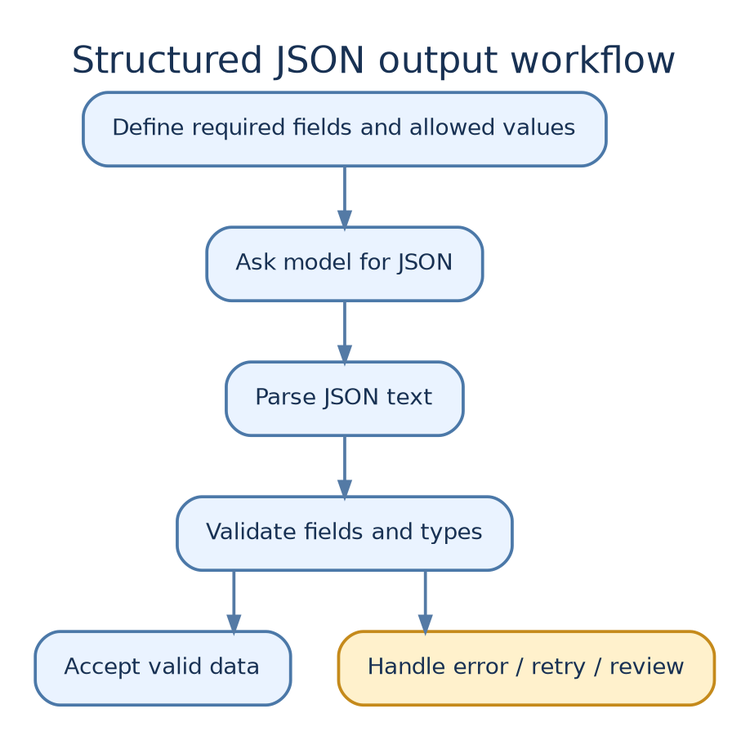

### Real-world example

A customer-support system receives a message about being charged twice. It may turn the message into structured fields so a workflow can route the case to the billing team. A human or trusted billing system may still need to confirm the actual transaction.

### Example

In [ ]:
import json

response_text = '''{
  "category": "billing",
  "priority": "medium",
  "needs_human": true
}'''

allowed_categories = {"billing", "technical", "account", "other"}
allowed_priorities = {"low", "medium", "high"}
required_fields = {"category", "priority", "needs_human"}

try:
    ticket = json.loads(response_text)
    if not isinstance(ticket, dict):
        raise ValueError("The JSON root must be an object")
    if set(ticket) != required_fields:
        raise ValueError("The fields do not match the required schema")
    if ticket["category"] not in allowed_categories:
        raise ValueError("Unsupported category")
    if ticket["priority"] not in allowed_priorities:
        raise ValueError("Unsupported priority")
    if not isinstance(ticket["needs_human"], bool):
        raise ValueError("needs_human must be true or false")
    print("Valid ticket:", ticket)
except (json.JSONDecodeError, ValueError) as error:
    print("Invalid response:", error)

## 10. Hallucinations, context limitations, and evaluation

### Explanation

A **hallucination** is when a model produces a statement that sounds convincing but is false, unsupported, or invented. A model may also give an incomplete answer because it did not receive the right information, misunderstood the request, or had too much context to handle reliably.

Why hallucinations can happen:

- The model generates likely text; it is not automatically checking every statement against a trusted source.
- The prompt may be vague or missing important details.
- The answer may require current information that was not supplied.
- The model may not know that it does not know.
- A long context can contain conflicting or easy-to-miss details.

Ways to reduce risk:

1. Provide relevant, trusted context.
2. Ask the model to distinguish supported facts from unknown information.
3. Use retrieval or tools for information that needs verification.
4. Validate calculations, JSON, dates, IDs, and business rules in code.
5. Require human review for high-impact decisions.
6. Evaluate with a representative set of test cases, including edge cases and wrong-answer cases.

**Evaluation** means measuring whether model outputs meet the task requirements. One test or one good response is not enough to prove a system is reliable. The right metric depends on the task: exact match, factual support, classification precision/recall, human ratings, latency, cost, and safety checks may all matter.

### Flow chart

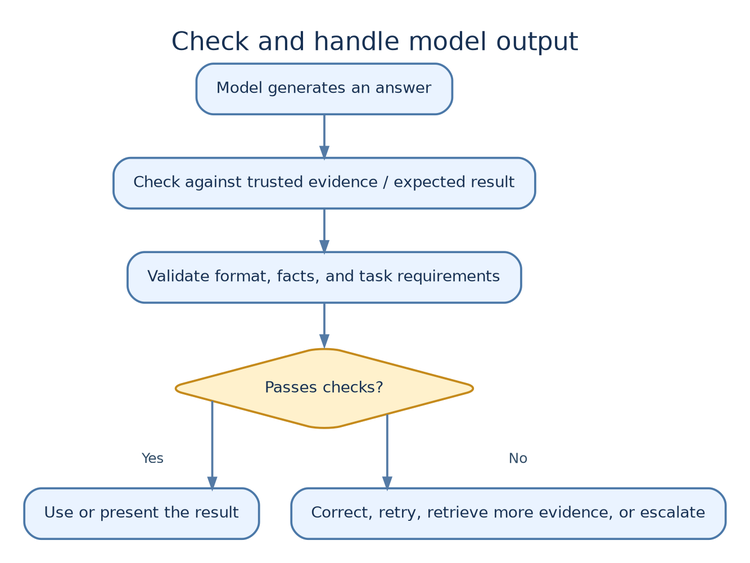

### Real-world example

An AI says a company policy allows a refund within 60 days. If the actual policy says 30 days, the fluent answer is still wrong. A safer application retrieves the current policy and verifies the claim before presenting it.

### Example: exact-match evaluation

This is a tiny demonstration of one metric. Real evaluations usually need more examples and task-specific checks.

In [ ]:
test_cases = [
    {"expected": "Paris", "actual": "Paris"},
    {"expected": "Tokyo", "actual": "Tokio"},
    {"expected": "Canberra", "actual": "Canberra"},
]

correct = sum(
    case["expected"].casefold() == case["actual"].casefold()
    for case in test_cases
)
accuracy = correct / len(test_cases)

print(f"Correct: {correct} / {len(test_cases)}")
print(f"Exact-match accuracy: {accuracy:.1%}")
print("This metric is useful for exact answers but not enough for every task.")

## 11. Hosted models versus local models

### Explanation

The main difference is **where the model runs and where the computing happens**.

- A **hosted model** runs on infrastructure managed by a provider. You typically access it through a website or API over a network.
- A **local model** runs on your own computer or on a server you manage. You install or download a model and run it using compatible software.

The terms describe where the model runs, not automatically how capable it is. A hosted model is not always better, and a local model is not always more private by default. The specific model, hardware, configuration, and data flow matter.

### Hosted models — advantages

- Usually easy to start using.
- Can provide access to models that need powerful hardware.
- Provider manages much of the infrastructure and model serving.
- Can be easier to scale an application, depending on provider limits and cost.

### Hosted models — disadvantages

- Usually need an internet connection.
- API requests or subscriptions may cost money.
- Prompts may be sent to the provider; check data-handling and retention policies.
- You have less control over infrastructure and provider changes.
- Outages, rate limits, and pricing changes can affect your application.

### Local models — advantages

- Can run offline after model files and required software are installed.
- Gives you more direct control over where inference happens and how data is handled.
- Can avoid per-request API fees, though hardware, electricity, and maintenance still cost money.
- Useful for experimentation and learning about model serving.

### Local models — disadvantages

- Requires enough storage, RAM, and processing power.
- Large models may run slowly or not fit on your hardware.
- You manage installation, updates, security, and troubleshooting.
- Quality varies; some local models may be less capable than particular hosted models on a task.
- You manage capacity and scaling if many people use your application.

### Flow chart

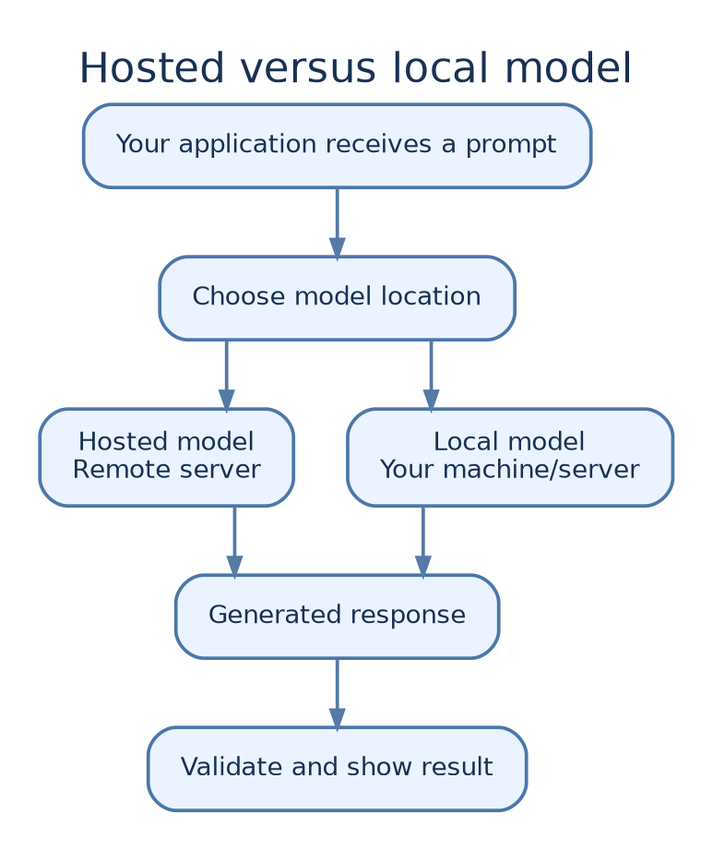

### Real-world examples

- **Hosted:** A Python web application calls a provider's model API. Your application sends a request over the network and receives the answer.
- **Local:** You install Ollama, download a compatible model, and send requests to a local service such as `http://localhost:11434`.

### Example: compare the approaches

This cell only prints a comparison; it does not connect to a hosted provider or run a local model.

In [ ]:
comparison = {
    "Hosted model": {
        "runs_where": "Provider-managed server",
        "network": "Usually requires internet",
        "main_benefit": "Easy access to powerful managed infrastructure",
        "main_tradeoff": "Provider policies, availability, and possible usage costs",
    },
    "Local model": {
        "runs_where": "Your computer or server",
        "network": "Can work offline after setup",
        "main_benefit": "More direct control over model execution and data flow",
        "main_tradeoff": "You provide hardware and manage setup and maintenance",
    },
}

for option, details in comparison.items():
    print(f"\n{option}")
    for label, value in details.items():
        print(f"  {label.replace('_', ' ').title()}: {value}")

## 12. End-to-end flow: how an LLM feature fits into an application

The concepts above often work together in a real product. Imagine a help-desk assistant that answers a question about a company policy.

### Flow chart

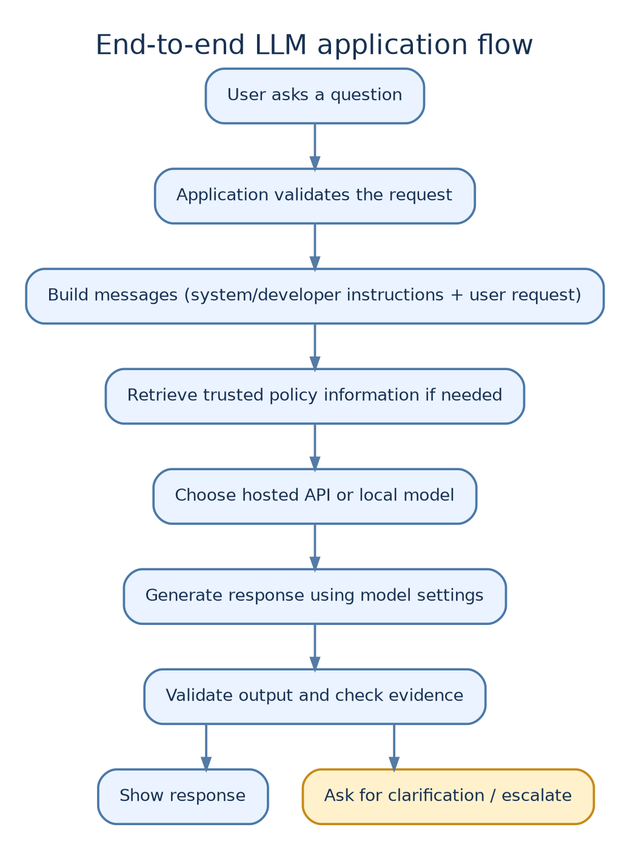

### Real-world example

User: `Can I return a headset after 45 days?`

A safer assistant should not guess. It retrieves the current return policy, checks the stated return window, asks for missing details if needed, and explains the result. If the answer is returned as JSON for an application workflow, the backend parses and validates it before taking action.

### Example: a simplified workflow

This example demonstrates application-side validation and decision-making using fixed sample data. It does not call an LLM.

In [ ]:
policy = {"return_window_days": 30}
customer_days_since_purchase = 45

if customer_days_since_purchase <= policy["return_window_days"]:
    decision = "Within the stated return window; continue with the return process."
else:
    decision = "Outside the stated return window; check exceptions or escalate to support."

print("Policy return window:", policy["return_window_days"], "days")
print("Days since purchase:", customer_days_since_purchase)
print("Application decision:", decision)
print("A real application must use the current trusted policy and account facts.")